# RouteRanker – a machine-learning model that learns from real transit data
This notebook trains, evaluates and saves the model **step by step on real GTFS feeds** (Pune PMPML, Chennai MTC, Bengaluru BMTC).

**What the model learns (and what it does not).** Published GTFS feeds contain *schedules*, not passengers. So the model learns how each operator
**allocates service**: given a route's geometry and network position (length, stops, connectivity, distance to the core, overlap, hour of day…),
how many trips does it get in that hour? Routes that get far fewer/more trips than comparable routes are flagged as
*relatively under-/over-served versus peers*. That is a **screening signal**; confirming crowding needs ridership data.

In [1]:
import sys, json, warnings; warnings.filterwarnings('ignore'); sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor
from src import learning as L
plt.rcParams.update({'figure.dpi': 90, 'axes.grid': True, 'grid.alpha': .3})
print(Path('../real_data/SOURCES.md').read_text()[:1500])

# Real GTFS feeds used for learning (unmodified downloads, retrieved 2026-10-23)

| City | Operator | File | Original URL | Licence / terms | Notes |
|---|---|---|---|---|---|
| Pune | PMPML | `Pune_PMPML_gtfs.zip` | https://raw.githubusercontent.com/croyla/pmpml-gtfs/main/pmpml_gtfs_compat.zip | see repository `croyla/pmpml-gtfs` | Auto-generated from PMPML data; "compat" variant merges both directions into one route. 315 routes, 10,128 trips. |
| Chennai | MTC (+ CMRL, Southern Railway in same file) | `Chennai_MTC_gtfs.zip` | https://raw.githubusercontent.com/ungalsoththu/ChennaiGTFS/main/data/chennai-unified-gtfs.zip | see repository `ungalsoththu/ChennaiGTFS` | Multi-modal; only bus routes (route_type 3, 4,611 entries) are used. |
| Bengaluru | BMTC | `Bengaluru_BMTC_gtfs.zip` | https://raw.githubusercontent.com/Vonter/bmtc-gtfs/main/gtfs/bmtc.zip | ODbL 1.0 (some content © BMTC) | **Unofficial**, scraped from the Namma BMTC app; only routes with live tracking are included, so it i

## 1. The real data
The corpus was built by `python -m src.learn corpus ...` from the three downloaded feeds (validated, cleaned, row counts logged). One row = one route in one hour of a typical weekday.

In [2]:
T, I, metas = L.corpus_load()
print(pd.DataFrame(metas)[['name','source','routes','rows','added']].to_string(index=False))
print('\nrow-level table:', T.shape); T[['city','route_uid','hour','trips','city_scale'] + L.FEATURES[:6]].head(8)

     name                  source  routes  rows               added
Bengaluru Bengaluru_BMTC_gtfs.zip    4408 39182 2026-11-02T13:01:16
  Chennai    Chennai_MTC_gtfs.zip    3918 34682 2026-11-02T13:00:36
     Pune     Pune_PMPML_gtfs.zip     315  3383 2026-11-02T13:00:06

row-level table: (77247, 31)


,city,route_uid,hour,trips,city_scale,hour,hour_sin,hour_cos,rel_pos,hrs_from_start,hrs_to_end
0,Bengaluru,Bengaluru|3447,8,1.0,1.468149,8,8.660254e-01,-0.500000,0.0,0,9
1,Bengaluru,Bengaluru|3447,9,0.0,1.468149,9,7.071068e-01,-0.707107,0.1,1,8
2,Bengaluru,Bengaluru|3447,10,0.0,1.468149,10,5.000000e-01,-0.866025,0.2,2,7
3,Bengaluru,Bengaluru|3447,11,0.0,1.468149,11,2.588190e-01,-0.965926,0.3,3,6
4,Bengaluru,Bengaluru|3447,12,0.0,1.468149,12,1.224647e-16,-1.000000,0.4,4,5
5,Bengaluru,Bengaluru|3447,13,0.0,1.468149,13,-2.588190e-01,-0.965926,0.5,5,4
6,Bengaluru,Bengaluru|3447,14,0.0,1.468149,14,-5.000000e-01,-0.866025,0.6,6,3
7,Bengaluru,Bengaluru|3447,15,0.0,1.468149,15,-7.071068e-01,-0.707107,0.7,7,2


**Features** (all computed from the schedule and stop geography; the route's own timetable is *not* an input):
`hour` (+ cyclic encoding, position in the service day, peak flags) · `route_length_km`, `n_stops`, `avg_stop_spacing_km`, `trip_duration_min`, `avg_speed_kmph`, `service_span_hr` ·
`mean_conn`/`max_conn` (how many routes serve its stops) · `frac_stops_shared`, `hub_frac`, `max_overlap` · `mean_dist_norm`/`min_dist_norm` (distance to the city core, normalised by city size) ·
`other_service_log` (trips of *other* routes at its stops).

**Target:** trips in that route-hour, expressed **relative to the city's mean** (operators differ hugely in fleet size, so the model learns structure, not scale).
City-level descriptors were deliberately removed: with only three cities they act as a city ID and the model would just memorise operators.

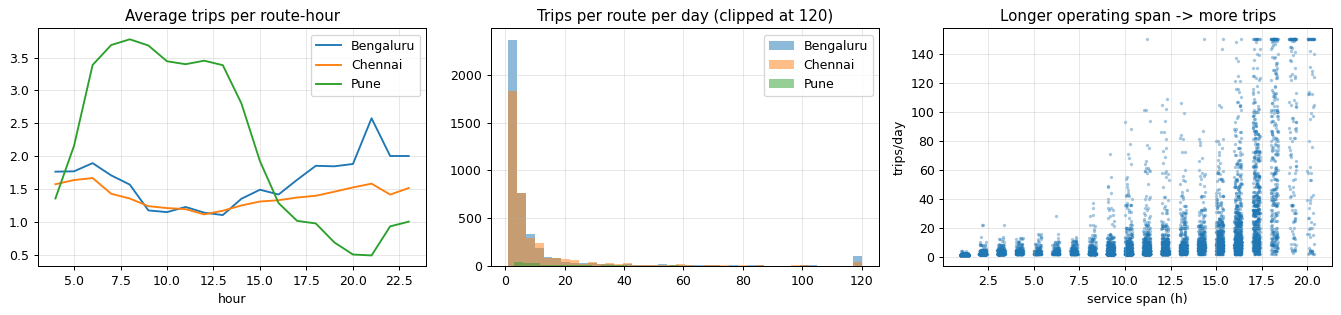

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for c, g in T.groupby('city'): ax[0].plot(g.groupby('hour').trips.mean(), label=c)
ax[0].set(title='Average trips per route-hour', xlabel='hour'); ax[0].legend()
for c, g in T.groupby('city'): ax[1].hist(g.groupby('route_uid').trips.sum().clip(upper=120), bins=40, alpha=.5, label=c)
ax[1].set(title='Trips per route per day (clipped at 120)'); ax[1].legend()
r = T.drop_duplicates('route_uid'); ax[2].scatter(r.service_span_hr + np.random.rand(len(r))*.4, r.route_uid.map(T.groupby('route_uid').trips.sum()).clip(upper=150), s=3, alpha=.3)
ax[2].set(title='Longer operating span -> more trips', xlabel='service span (h)', ylabel='trips/day'); plt.tight_layout(); plt.show()

## 2. Baselines first
A model only 'learns' if it beats simple rules. Baseline 0 = always the average; baseline 1 = average for that hour of the day (ignores the route entirely).

## 3. Training and honest evaluation: learning each city's network
For every city we train on **its own routes** and test on **routes the model has never seen** (5-fold, grouped by route so a route is never in both sets).

MAE in trips per route-hour on held-out routes (lower is better)


city,Bengaluru,Chennai,Pune
model,,,
baseline_hour_mean,1.591,1.248,2.151
baseline_mean,1.619,1.259,2.313
gradient_boosting,1.064,0.843,1.576
poisson_linear,1.390,1.133,1.812
random_forest,1.121,0.871,1.649


city,Bengaluru,Chennai,Pune
R-squared,,,
baseline_hour_mean,0.012,0.006,0.091
baseline_mean,-0.000,-0.000,-0.007
gradient_boosting,0.409,0.428,0.356
poisson_linear,0.261,0.199,0.274
random_forest,0.401,0.429,0.379


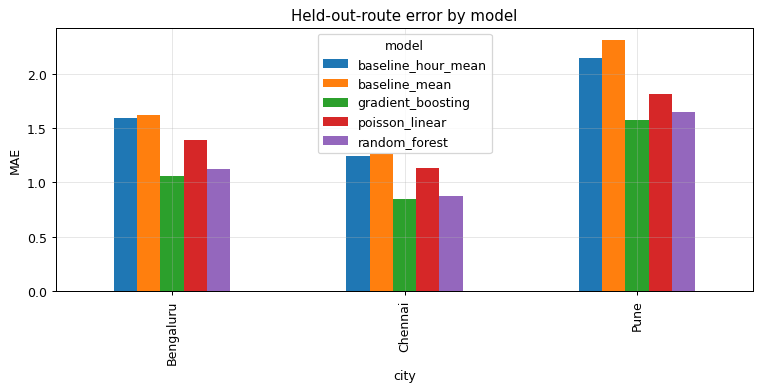

In [4]:
from sklearn.model_selection import GroupKFold
res = []
for city in sorted(T.city.unique()):
    D = T[T.city == city].reset_index(drop=True)
    for name in ['baseline_mean', 'baseline_hour_mean', 'poisson_linear', 'random_forest', 'gradient_boosting']:
        oof = np.zeros(len(D))
        for a, b in GroupKFold(5).split(D, groups=D.route_uid):
            oof[b], _ = L._fit_predict(name, D.iloc[a], D.iloc[b])          # fit on relative target, predict, rescale
        s = L.score(D.trips, oof, D.route_uid.values); res.append(dict(city=city, model=name, **s))
R = pd.DataFrame(res); piv = R.pivot(index='model', columns='city', values='mae').round(3)
print('MAE in trips per route-hour on held-out routes (lower is better)'); display(piv)
display(R.pivot(index='model', columns='city', values='r2').round(3).rename_axis('R-squared'))
piv.T.plot.bar(figsize=(10, 3.8), title='Held-out-route error by model'); plt.ylabel('MAE'); plt.show()

In [5]:
base = R[R.model == 'baseline_hour_mean'].set_index('city').mae; gb = R[R.model == 'gradient_boosting'].set_index('city').mae
print('Error reduction of the learned model vs the best baseline:'); print((1 - gb / base).round(3).rename('skill'))

Error reduction of the learned model vs the best baseline:
city
Bengaluru    0.331
Chennai      0.325
Pune         0.267
Name: skill, dtype: float64


## 4. Does it really *learn from data*? Learning curve
Fixed held-out routes; the model is trained on growing numbers of routes. If it learns, error falls and R² rises as it sees more data.

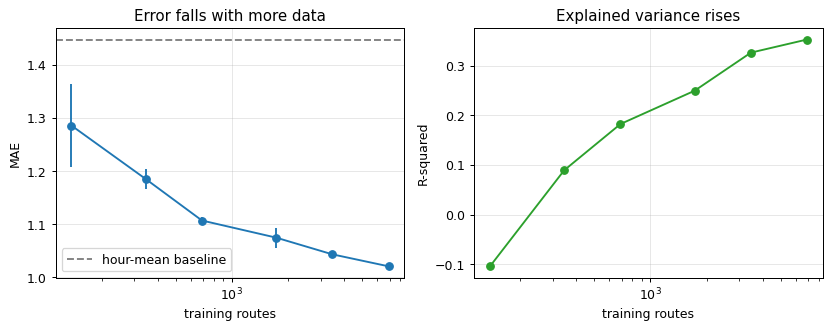

,frac,n_routes,mae,mae_sd,r2
0,0.02,138,1.286,0.078,-0.104
1,0.05,345,1.185,0.019,0.089
2,0.10,691,1.107,0.007,0.182
3,0.25,1728,1.075,0.019,0.250
4,0.50,3456,1.043,0.002,0.326
5,1.00,6913,1.021,0.000,0.353


In [6]:
lc = L.learning_curve(T, seeds=2); P = pd.DataFrame(lc['points'])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].errorbar(P.n_routes, P.mae, yerr=P.mae_sd, marker='o'); ax[0].axhline(lc['baseline_hour_mean_mae'], ls='--', c='gray', label='hour-mean baseline'); ax[0].set(xscale='log', xlabel='training routes', ylabel='MAE', title='Error falls with more data'); ax[0].legend()
ax[1].plot(P.n_routes, P.r2, marker='o', c='C2'); ax[1].set(xscale='log', xlabel='training routes', ylabel='R-squared', title='Explained variance rises'); plt.show(); P.round(3)

## 5. Generalising to a city the model has never seen (leave-one-city-out) – the honest limit
Train on two cities, test on the third. Values come from the saved model card (`models/model_card.json`, produced by `python -m src.learn train`).

In [7]:
card = json.load(open('../models/model_card.json'))
lo = pd.DataFrame({m: {c: v['mae'] for c, v in d.items()} for m, d in card['loco'].items()}).round(3); display(lo.rename_axis('unseen city (MAE)'))
display(pd.DataFrame({m: {c: v['r2'] for c, v in d.items()} for m, d in card['loco'].items()}).round(3).rename_axis('unseen city (R-squared)'))

,baseline_mean,baseline_hour_mean,poisson_linear,random_forest,gradient_boosting
unseen city (MAE),,,,,
Bengaluru,1.618,1.599,1.527,1.579,1.443
Chennai,1.259,1.264,1.170,1.183,1.088
Pune,2.301,2.393,2.653,3.204,2.963


,baseline_mean,baseline_hour_mean,poisson_linear,random_forest,gradient_boosting
unseen city (R-squared),,,,,
Bengaluru,0.0,0.007,0.132,0.052,0.079
Chennai,0.0,-0.001,0.169,0.102,0.034
Pune,0.0,-0.068,-0.606,-1.507,-0.998


**Reading this honestly:** with only three operators, knowledge transfers weakly between cities (Pune is even worse than the baseline), because each operator schedules differently.
That is why RouteRanker **learns from the feed you give it** (section 3) and only uses the pooled model as a prior. More real cities in the corpus will improve cross-city transfer; the learning loop (section 8) makes adding them one command.

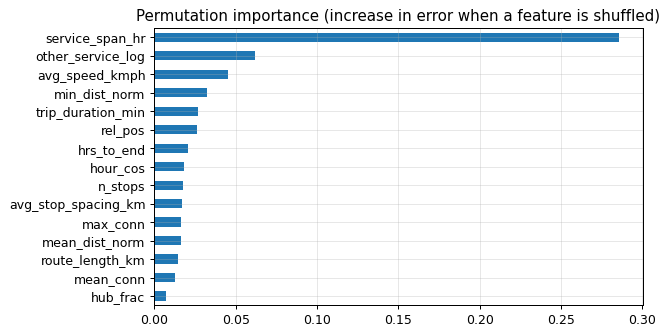

In [8]:
imp = pd.Series(card['permutation_importance']).sort_values(); imp.plot.barh(figsize=(7, 4), title='Permutation importance (increase in error when a feature is shuffled)'); plt.show()

## 6. Using what was learned: peer comparison of routes
For each route: actual daily trips vs the trips the model expects for a comparable route (predicted on held-out routes). Only the extreme tails are flagged.

flag
in line with peers                  7775
relatively over-served vs peers      433
relatively under-served vs peers     433


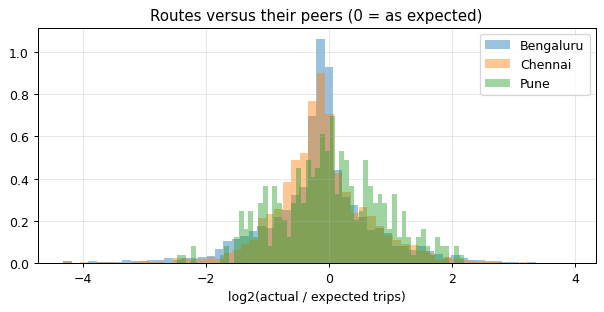

Most relatively UNDER-served vs peers (candidates to check for crowding, needs ridership data):


,city,route_short_name,route_long_name,actual_trips,expected_trips,ratio,flag
1599,Bengaluru,D4-JBS4T,Jayanagara 4th T Block ⇔ Depot-04 Jayanagara,2.0,78.55,0.03,relatively under-served vs peers
4507,Chennai,121M,M.G.R.Koyambedu TO Moolakadai,3.0,107.22,0.03,relatively under-served vs peers
4456,Chennai,27B,M.G.R.Koyambedu TO Avadi B.T,2.0,66.55,0.03,relatively under-served vs peers
1638,Bengaluru,BC-7B BDH-PSBS,Peenya Satellite Bus Station (Basaveshwara) ⇔ ...,4.0,123.86,0.03,relatively under-served vs peers
5919,Chennai,27B CT,M.G.R.Koyambedu TO Triplicane,4.0,104.09,0.04,relatively under-served vs peers
6499,Chennai,21G,Kilambakkam B.S TO Mandaveli,4.0,97.08,0.04,relatively under-served vs peers
1133,Bengaluru,243-A,Upkar Residency Layout ⇔ Kempegowda Bus Station,2.0,43.73,0.05,relatively under-served vs peers
374,Bengaluru,401-PS,Yelahanka Old Town ⇔ Peenya Satellite Bus Stat...,2.0,38.08,0.05,relatively under-served vs peers
8515,Pune,337,Dsk Vishwa ⇆ Nigdi Bhakti Shakti Stand,9.0,50.19,0.18,relatively under-served vs peers
8404,Pune,184,Ramdara ⇆ Hadapsar Gadital Solapur Road,9.0,47.15,0.19,relatively under-served vs peers


In [9]:
G = pd.read_csv('../outputs/peer_gap.csv'); print(G.flag.value_counts().to_string())
fig, ax = plt.subplots(figsize=(8, 3.4))
for c, g in G.groupby('city'): ax.hist(np.log2(g.ratio.clip(.05, 20)), bins=60, alpha=.45, label=c, density=True)
ax.set(xlabel='log2(actual / expected trips)', title='Routes versus their peers (0 = as expected)'); ax.legend(); plt.show()
cols = ['city', 'route_short_name', 'route_long_name', 'actual_trips', 'expected_trips', 'ratio', 'flag']
print('Most relatively UNDER-served vs peers (candidates to check for crowding, needs ridership data):')
display(G[G.flag.str.contains('under')].sort_values('ratio').groupby('city').head(4)[cols].round(2))

## 7. Saving, loading and applying the model to any feed
The trained model is a file: `models/service_model.joblib` (+ `model_card.json`, `registry.json`). `predict_feed` learns from the feed it is given and checks reliability.

In [10]:
from src import gtfs_validation as gv
art = L.load_model(); print('model version', art['version'], '| best model:', art['best'], '| trained on', art['cities'])
feed = gv.read_zip_safely('../real_data/Pune_PMPML_gtfs.zip')
out, val, rep = L.predict_feed(art, feed, 'PuneCheck', mode='auto')
print('validation:', val['status'], '| mode:', out['mode'].iloc[0], '| skill on held-out routes: %.2f' % out['model_skill'].iloc[0]); print(out.flag.value_counts().to_string())

model version 20261102-59ba8f7cc6 | best model: gradient_boosting | trained on ['Bengaluru', 'Chennai', 'Pune']


validation: pass | mode: self-learned on this feed | skill on held-out routes: 0.27
flag
in line with peers                  283
relatively over-served vs peers      16
relatively under-served vs peers     16


## 8. Learning from new data (the learning loop)
Add any new city's GTFS and the model **retrains on everything**; a champion/challenger rule decides whether the new version replaces the old one:
```
python -m src.learn add --gtfs path\to\new_city.zip --name Hyderabad
```
The registry below is the version history written by the code.

In [11]:
pd.DataFrame(json.load(open('../models/registry.json')))[['version', 'trained_at', 'cities', 'n_routes', 'best', 'cv_mae', 'promoted', 'reason']]

,version,trained_at,cities,n_routes,best,cv_mae,promoted,reason
0,20261102-59ba8f7cc6,2026-11-02T13:16:23,"[Bengaluru, Chennai, Pune]",8641,gradient_boosting,1.041944,True,first model


## 9. Limitations
* Learns **service allocation**, not passenger demand: a route flagged "under-served vs peers" may simply be a low-demand route. Confirm with ridership/APC data before changing service.
* Cross-city transfer is weak with 3 cities (section 5); per-feed learning is the supported use.
* The Bengaluru feed is unofficial and covers only routes with live tracking; Pune's is auto-generated; Chennai's contains non-bus modes (filtered) and some junk identifiers (flagged by validation).
* No causal claims; no cost or passenger-impact figures are produced.